# Dhimas Sena Rahmantara - 26 MTTK A - Tugas 3 Applied Mathematics

Sumber Data: https://archive.ics.uci.edu/dataset/2/adult

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
import os

In [2]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

In [3]:
# fetch dataset
adult = fetch_ucirepo(id=2)

In [64]:
adult.data.features

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States
48838,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States


In [5]:
adult.data.targets

,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K
...,...
48837,<=50K.
48838,<=50K.
48839,<=50K.
48840,<=50K.


In [7]:
df = pd.concat([adult.data.features, adult.data.targets], axis=1)
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K.
48838,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States,<=50K.
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K.
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K.


In [10]:
# hilangkan titik di kolom income
df['income'] = df['income'].str.strip().str.rstrip('.')
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K
48838,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States,<=50K
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [12]:
df.isnull().sum()

,0
age,0
workclass,963
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,966
relationship,0
race,0
sex,0


In [13]:
print(df.duplicated().sum())

48


In [14]:
df = df.dropna()
df = df.drop_duplicates()

In [15]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [16]:
print(df.duplicated().sum())

0


In [17]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,47573.0,NaN,NaN,NaN,38.648771,13.55699,17.0,28.0,37.0,48.0,90.0
workclass,47573,9,Private,33671,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,47573.0,NaN,NaN,NaN,189731.936182,105582.885347,12285.0,117585.0,178282.0,237713.0,1490400.0
education,47573,16,HS-grad,15430,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,47573.0,NaN,NaN,NaN,10.091628,2.567288,1.0,9.0,10.0,12.0,16.0
marital-status,47573,7,Married-civ-spouse,21953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,47573,15,Prof-specialty,6103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,47573,6,Husband,19383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,47573,5,White,40742,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,47573,2,Male,31904,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Populasi Awal

In [53]:
# persentase kolom target income pada populasi awal
df.value_counts(df['income'], normalize=True)

,proportion
income,
<=50K,0.757531
>50K,0.242469


# Random Sampling terhadap Populasi

In [54]:
# random sampling dengan 1000 sample
sample_rs = df.sample(n=1000, random_state=42)
sample_rs

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
41678,37,Self-emp-not-inc,31095,Assoc-voc,11,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,60,United-States,>50K
6837,23,State-gov,186634,12th,8,Never-married,Exec-managerial,Not-in-family,White,Male,0,0,40,United-States,<=50K
38350,31,Private,144990,HS-grad,9,Married-spouse-absent,Machine-op-inspct,Unmarried,Black,Female,0,0,40,United-States,<=50K
26712,70,Private,89787,HS-grad,9,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,20,United-States,<=50K
42348,39,Private,35890,Bachelors,13,Married-civ-spouse,Sales,Husband,White,Male,0,0,50,United-States,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33280,35,Private,179579,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,1977,48,United-States,>50K
35306,51,Private,166461,11th,7,Divorced,Machine-op-inspct,Unmarried,Black,Female,5455,0,40,United-States,<=50K
5542,40,Self-emp-inc,169878,Assoc-acdm,12,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,>50K
6927,55,Private,109015,Some-college,10,Divorced,Adm-clerical,Not-in-family,White,Female,0,0,38,United-States,<=50K


In [55]:
# persentase kolom target income menggunakan random sampling
sample_rs.value_counts(df['income'], normalize=True)

,proportion
income,
<=50K,0.731
>50K,0.269


# Stratified Sampling pada Populasi

In [56]:
from sklearn.model_selection import train_test_split

In [60]:
# stratified sampling dengan 1000 sample
sample_stratified, _ = train_test_split(
    df, train_size=1000, stratify=df["income"], random_state=42
)
sample_stratified

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
11375,37,State-gov,186934,Some-college,10,Married-civ-spouse,Other-service,Husband,White,Male,0,0,40,United-States,<=50K
26813,26,Private,189219,Assoc-acdm,12,Never-married,Adm-clerical,Not-in-family,White,Female,0,0,8,United-States,<=50K
1865,60,?,386261,Bachelors,13,Married-spouse-absent,?,Unmarried,Black,Female,0,0,15,United-States,<=50K
32864,26,Private,98114,HS-grad,9,Divorced,Exec-managerial,Own-child,White,Female,0,0,40,United-States,<=50K
1977,35,Private,343403,Some-college,10,Never-married,Sales,Not-in-family,White,Female,0,0,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19548,54,?,172991,HS-grad,9,Married-civ-spouse,?,Husband,White,Male,0,0,40,United-States,<=50K
358,42,Private,111949,HS-grad,9,Married-civ-spouse,Adm-clerical,Wife,White,Female,0,0,35,United-States,<=50K
5200,43,Federal-gov,144778,Bachelors,13,Never-married,Exec-managerial,Not-in-family,White,Male,0,0,40,United-States,>50K
23833,51,Private,57101,9th,5,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K


In [65]:
# persentase kolom target income menggunakan stratified sampling
sample_stratified.value_counts(df['income'], normalize=True)

,proportion
income,
<=50K,0.758
>50K,0.242


# Insight
* Sampling yang dilakukan menggunakan metode stratified sampling lebih mendekati persentase / proporsi jumlah populasi daripada metode random sampling.
* Hal ini dibuktikan dengan persentase kolom target pada stratified sampling yang besarnya mendekati persentase kolom target pada populasi awal, yakni dengan perbandingan 75,8% orang dengan pendapatan <= 50K dan 24,2% dengan pendapatan > 50K.
* Berbeda dengan random sampling yang memberikan persentase 73,1% untuk orang dengan pendapatan <= 50K dan 26,9% dengan pendapatan > 50 K.
* Sehingga dari perbandingan tersebut, metode stratified sampling lebih baik daripada random samling karena dapat mempertahankan persentase / proporsi dari populasi awal. Sedangkan pada random sampling, hasil sample bisa mengalami perubahan.


# Statistik Deskriptif pada Keseluruhan Populasi

In [71]:
print(df['age'].describe())
print()

modus_age = df['age'].mode()
print("Modus Usia :\n", modus_age)

q1_age = df['age'].quantile(0.25)
q2_age = df['age'].quantile(0.5)
q3_age = df['age'].quantile(0.75)
iqr_age = q3_age - q1_age
print()

print("Q1 usia :", q1_age)
print("Q2 usia :", q2_age)
print("Q3 usia :", q3_age)
print("IQR usia:", iqr_age)

batas_bawah_age = q1_age - (1.5 * iqr_age)
batas_atas_age = q3_age + (1.5 * iqr_age)

print("Batas Bawah Outlier Usia:", batas_bawah_age)
print("Batas Atas Outlier Usia:", batas_atas_age)
print()

print(f"Skewness Usia: {df['age'].skew()}")
print(f"Kurtosis Usia: {df['age'].kurt()}")


count    47573.000000
mean        38.648771
std         13.556990
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64

Modus Usia :
 0    36
Name: age, dtype: int64

Q1 usia : 28.0
Q2 usia : 37.0
Q3 usia : 48.0
IQR usia: 20.0
Batas Bawah Outlier Usia: -2.0
Batas Atas Outlier Usia: 78.0

Skewness Usia: 0.5505691110673596
Kurtosis Usia: -0.17327176421603596


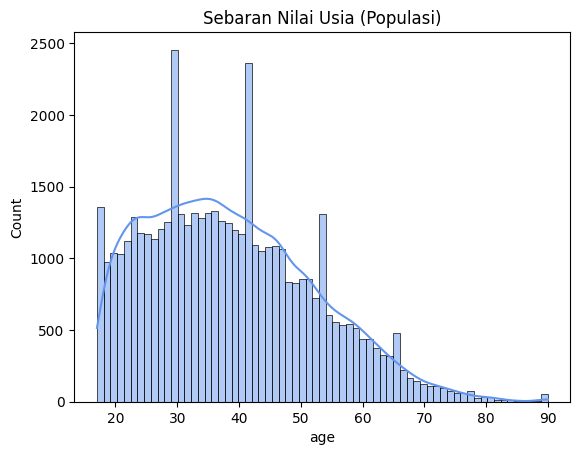

In [72]:
sns.histplot(df['age'], kde=True, color='cornflowerblue')
plt.title(f"Sebaran Nilai Usia (Populasi)")
plt.show()

In [77]:
print(sample_rs['age'].describe())
print()

modus_age = sample_rs['age'].mode()
print("Modus Usia :\n", modus_age)

q1_age_rs = sample_rs['age'].quantile(0.25)
q2_age_rs = sample_rs['age'].quantile(0.5)
q3_age_rs = sample_rs['age'].quantile(0.75)
iqr_age_rs = q3_age_rs - q1_age_rs
print()

print("Q1 usia :", q1_age_rs)
print("Q2 usia :", q2_age_rs)
print("Q3 usia :", q3_age_rs)
print("IQR usia:", iqr_age_rs)

batas_bawah_age_rs = q1_age_rs - (1.5 * iqr_age_rs)
batas_atas_age_rs = q3_age_rs + (1.5 * iqr_age_rs)

print("Batas Bawah Outlier Usia:", batas_bawah_age_rs)
print("Batas Atas Outlier Usia:", batas_atas_age_rs)
print()

print(f"Skewness Usia: {sample_rs['age'].skew()}")
print(f"Kurtosis Usia: {sample_rs['age'].kurt()}")

count    1000.000000
mean       39.373000
std        13.529779
min        17.000000
25%        29.000000
50%        38.000000
75%        48.000000
max        90.000000
Name: age, dtype: float64

Modus Usia :
 0    31
Name: age, dtype: int64

Q1 usia : 29.0
Q2 usia : 38.0
Q3 usia : 48.0
IQR usia: 19.0
Batas Bawah Outlier Usia: 0.5
Batas Atas Outlier Usia: 76.5

Skewness Usia: 0.4937129846207391
Kurtosis Usia: -0.34848244495600245


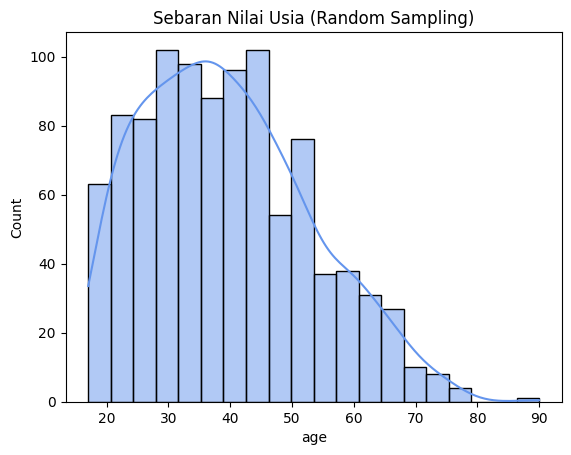

In [78]:
sns.histplot(sample_rs['age'], kde=True, color='cornflowerblue')
plt.title(f"Sebaran Nilai Usia (Random Sampling)")
plt.show()

In [80]:
print(sample_stratified['age'].describe())
print()

modus_age = sample_stratified['age'].mode()
print("Modus Usia :\n", modus_age)

q1_age_stra = sample_stratified['age'].quantile(0.25)
q2_age_stra = sample_stratified['age'].quantile(0.5)
q3_age_stra = sample_stratified['age'].quantile(0.75)
iqr_age_stra = q3_age_stra - q1_age_stra
print()

print("Q1 usia :", q1_age_stra)
print("Q2 usia :", q2_age_stra)
print("Q3 usia :", q3_age_stra)
print("IQR usia:", iqr_age_stra)

batas_bawah_age_stra = q1_age_stra - (1.5 * iqr_age_stra)
batas_atas_age_stra = q3_age_stra + (1.5 * iqr_age_stra)

print("Batas Bawah Outlier Usia:", batas_bawah_age_stra)
print("Batas Atas Outlier Usia:", batas_atas_age_stra)
print()

print(f"Skewness Usia: {sample_stratified['age'].skew()}")
print(f"Kurtosis Usia: {sample_stratified['age'].kurt()}")

count    1000.000000
mean       38.916000
std        13.632857
min        17.000000
25%        28.000000
50%        37.000000
75%        48.250000
max        90.000000
Name: age, dtype: float64

Modus Usia :
 0    25
Name: age, dtype: int64

Q1 usia : 28.0
Q2 usia : 37.0
Q3 usia : 48.25
IQR usia: 20.25
Batas Bawah Outlier Usia: -2.375
Batas Atas Outlier Usia: 78.625

Skewness Usia: 0.5058046179452191
Kurtosis Usia: -0.25394829380039186


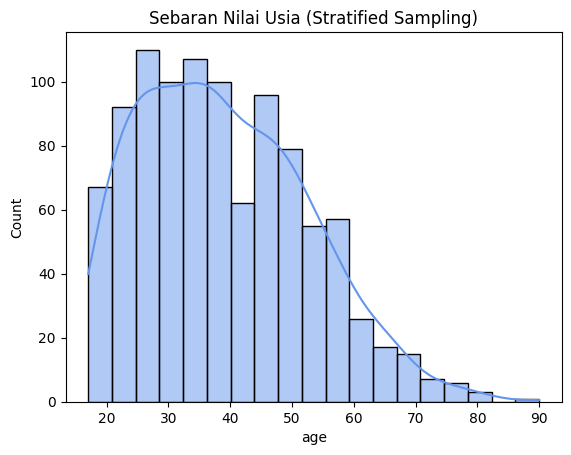

In [83]:
sns.histplot(sample_stratified['age'], kde=True, color='cornflowerblue')
plt.title(f"Sebaran Nilai Usia (Stratified Sampling)")
plt.show()